# D02 — Audit des données DIA & SPY

Ce notebook charge le snapshot Parquet, contrôle la qualité des données et produit les graphiques de cohérence. Toute la logique est dans `src/`.

**Règle anti-fuite :** ce notebook ne regarde que les prix historiques bruts. Aucune cible ni aucun décalage n'est calculé ici.

In [1]:
import os, sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

# Trouver la racine du projet (contient configs/frozen.yaml)
_candidate = Path.cwd()
for _ in range(6):
    if (_candidate / "configs" / "frozen.yaml").exists():
        break
    _candidate = _candidate.parent
else:
    raise RuntimeError("Racine du projet introuvable depuis " + str(Path.cwd()))
ROOT = _candidate
os.chdir(str(ROOT))
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

from src.data import load_ohlcv, load_closes
from src.quality import audit

# Dossiers de sortie
FIG = ROOT / "reports" / "d02" / "figures"
REP = ROOT / "reports" / "d02"
FIG.mkdir(parents=True, exist_ok=True)

print("Racine :", ROOT)

Racine : C:\Users\elbid\Documents\TREDING INTELEGENT\dia-quant-lab


## 1. Chargement du snapshot et résumé par fenêtre

In [2]:
ohlcv  = load_ohlcv()
closes = load_closes()

print(f"Lignes dans le snapshot  : {len(ohlcv):,}")
print(f"Tickers                  : {ohlcv['ticker'].unique().tolist()}")
print(f"Première séance commune  : {closes.index.min().date()}")
print(f"Dernière séance commune  : {closes.index.max().date()}")
print()

fenetres = {
    "Apprentissage": ("2018-01-01", "2022-12-31"),
    "Validation"   : ("2023-01-01", "2024-12-31"),
    "Test"         : ("2025-01-01", "2026-10-30"),
}
resume = []
for nom, (s, e) in fenetres.items():
    sub = closes[(closes.index >= s) & (closes.index <= e)]
    resume.append({
        "Fenêtre": nom,
        "Début"  : str(sub.index.min().date()),
        "Fin"    : str(sub.index.max().date()),
        "Séances": len(sub),
    })
df_resume = pd.DataFrame(resume)
print(df_resume.to_string(index=False))
df_resume


Lignes dans le snapshot  : 4,440
Tickers                  : ['DIA', 'SPY']
Première séance commune  : 2018-01-02
Dernière séance commune  : 2026-10-30

      Fenêtre      Début        Fin  Séances
Apprentissage 2018-01-02 2022-12-30     1259
   Validation 2023-01-03 2024-12-31      502
         Test 2025-01-02 2026-10-30      459


,Fenêtre,Début,Fin,Séances
0,Apprentissage,2018-01-02,2022-12-30,1259
1,Validation,2023-01-03,2024-12-31,502
2,Test,2025-01-02,2026-10-30,459


## 2. Tableau de contrôle qualité

In [3]:
rapport = audit(ohlcv)
rapport.to_csv(REP / "audit_qualite.csv", index=False)
print(f"Rapport sauvegardé : {REP / 'audit_qualite.csv'}")
print(f"Nombre de contrôles : {len(rapport)}")
print(f"Contrôles avec anomalies : {(rapport['nb_anomalies'] > 0).sum()}")
print()
rapport[rapport["nb_anomalies"] > 0]


Rapport sauvegardé : C:\Users\elbid\Documents\TREDING INTELEGENT\dia-quant-lab\reports\d02\audit_qualite.csv
Nombre de contrôles : 36
Contrôles avec anomalies : 3



,contrôle,ticker,nb_anomalies,détail
28,incoherence_ohlc_high_inferieur_max_OC,SPY,1,"[datetime.date(2018, 1, 11)]"
34,rendement_extreme_5sigma,DIA,11,"[{'date': datetime.date(2020, 3, 9), 'ret_pct'..."
35,rendement_extreme_5sigma,SPY,8,"[{'date': datetime.date(2020, 3, 9), 'ret_pct'..."


## 3. Graphique de cohérence — DIA et SPY en base 100

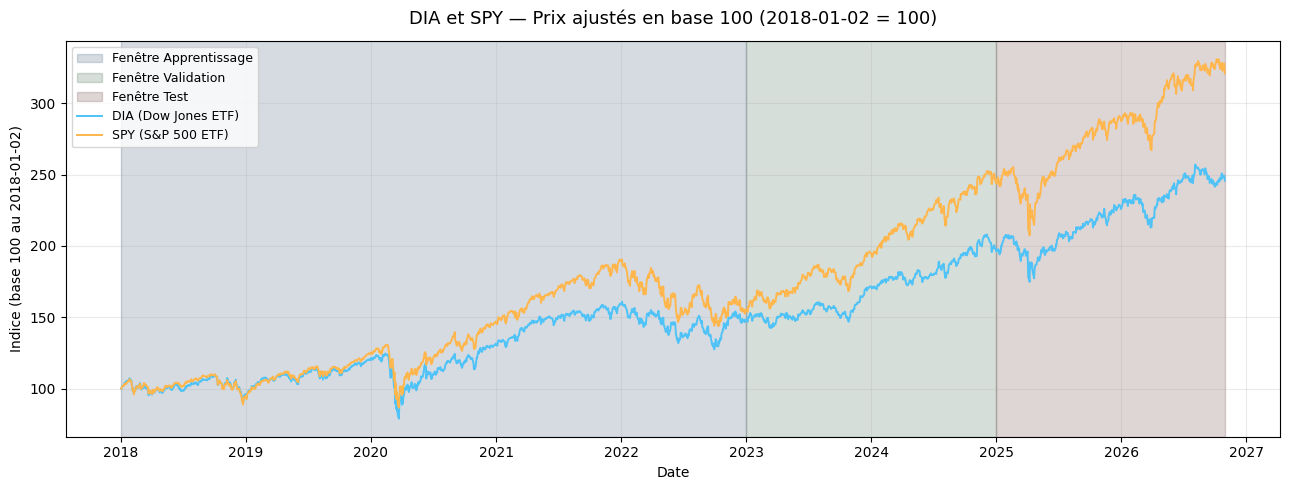

Figure sauvegardée : C:\Users\elbid\Documents\TREDING INTELEGENT\dia-quant-lab\reports\d02\figures\coherence_base100.png


In [4]:
fig, ax = plt.subplots(figsize=(13, 5))

# Fonds colorés par fenêtre
couleurs = {"Apprentissage": "#1a3a5c", "Validation": "#1a4a2a", "Test": "#4a1a1a"}
for nom, (s, e) in fenetres.items():
    ax.axvspan(pd.Timestamp(s), pd.Timestamp(e),
               alpha=0.18, color=couleurs[nom], label=f"Fenêtre {nom}")

# Séries en base 100
base = closes.iloc[0]
b100 = closes / base * 100

ax.plot(b100.index, b100["DIA"], color="#4fc3f7", linewidth=1.4, label="DIA (Dow Jones ETF)")
ax.plot(b100.index, b100["SPY"], color="#ffb74d", linewidth=1.4, label="SPY (S&P 500 ETF)")

ax.set_title("DIA et SPY — Prix ajustés en base 100 (2018-01-02 = 100)", fontsize=13, pad=12)
ax.set_xlabel("Date")
ax.set_ylabel("Indice (base 100 au 2018-01-02)")
ax.legend(loc="upper left", fontsize=9)
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(FIG / "coherence_base100.png", dpi=150)
plt.show()
print("Figure sauvegardée :", FIG / "coherence_base100.png")


## 4. Rendements journaliers DIA — anomalies marquées

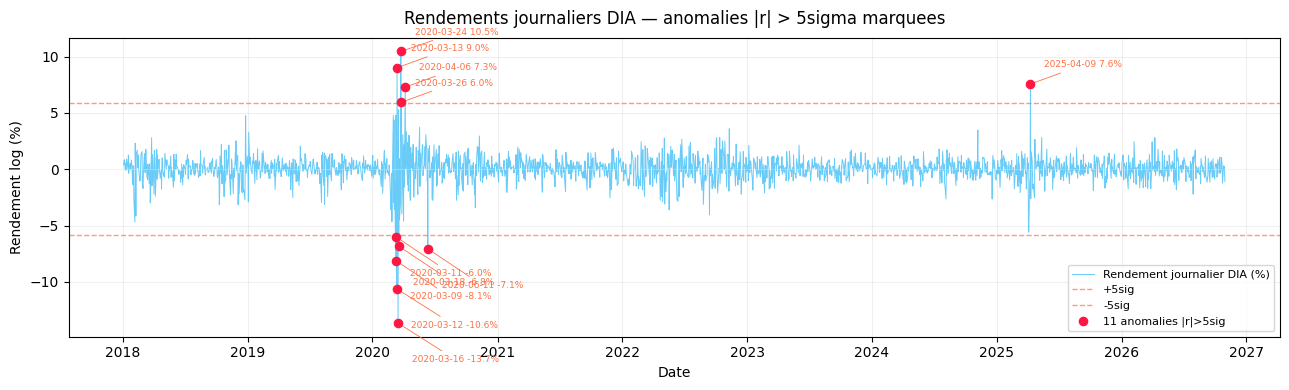

11 anomalies, sigma = 1.1706%


In [5]:
dia = closes['DIA'].sort_index()
ret_dia = np.log(dia / dia.shift(1)).dropna()
sigma   = ret_dia.std()
seuil   = 5 * sigma

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(ret_dia.index, ret_dia * 100, color='#4fc3f7', linewidth=0.7, alpha=0.85,
        label='Rendement journalier DIA (%)')
ax.axhline(0, color='white', linewidth=0.5, alpha=0.4)
ax.axhline( seuil * 100, color='#ff7043', linewidth=1, linestyle='--', alpha=0.7,
           label='+5sig')
ax.axhline(-seuil * 100, color='#ff7043', linewidth=1, linestyle='--', alpha=0.7,
           label='-5sig')

extremes = ret_dia[ret_dia.abs() > seuil]
n_ext = len(extremes)
ax.scatter(extremes.index, extremes * 100, color='#ff1744', zorder=5, s=35,
           label=str(n_ext) + ' anomalies |r|>5sig')
for d, v in extremes.items():
    label_txt = d.strftime('%Y-%m-%d') + ' ' + str(round(v*100,1)) + '%'
    ax.annotate(label_txt, xy=(d, v * 100),
                xytext=(10, 12 if v > 0 else -28),
                textcoords='offset points', fontsize=6.5, color='#ff7043',
                arrowprops=dict(arrowstyle='-', color='#ff7043', lw=0.6))

ax.set_title('Rendements journaliers DIA — anomalies |r| > 5sigma marquees', fontsize=12, pad=10)
ax.set_xlabel('Date')
ax.set_ylabel('Rendement log (%)')
ax.legend(fontsize=8, loc='lower right')
ax.grid(True, alpha=0.2)
fig.tight_layout()
fig.savefig(FIG / 'rendements_dia_anomalies.png', dpi=150)
plt.show()
print(str(n_ext) + ' anomalies, sigma = ' + str(round(sigma*100, 4)) + '%')


## 5. Nuage de points DIA contre SPY

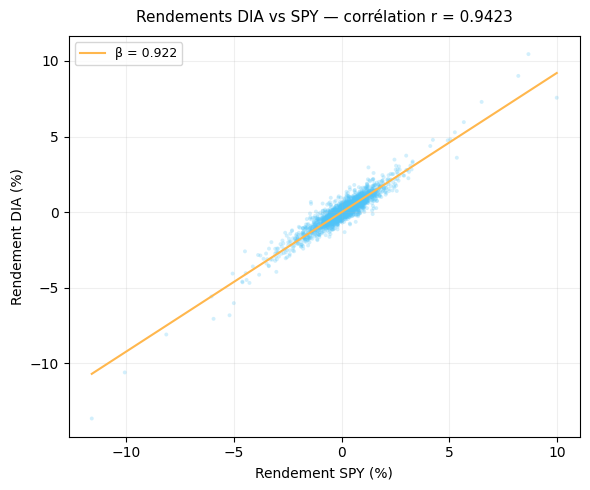

Corrélation DIA/SPY : 0.9423   Bêta : 0.9224


In [6]:
ret_spy = np.log(closes["SPY"] / closes["SPY"].shift(1)).dropna()
# Aligner sur les dates communes
idx = ret_dia.index.intersection(ret_spy.index)
x, y = ret_spy.loc[idx] * 100, ret_dia.loc[idx] * 100
corr = float(np.corrcoef(x, y)[0, 1])

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(x, y, alpha=0.25, s=8, color="#4fc3f7", edgecolors="none")

# Droite de régression
m = np.polyfit(x, y, 1)
xr = np.linspace(x.min(), x.max(), 200)
ax.plot(xr, np.polyval(m, xr), color="#ffb74d", linewidth=1.5, label=f"β = {m[0]:.3f}")

ax.set_title(f"Rendements DIA vs SPY — corrélation r = {corr:.4f}", fontsize=11, pad=10)
ax.set_xlabel("Rendement SPY (%)")
ax.set_ylabel("Rendement DIA (%)")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.2)
fig.tight_layout()
fig.savefig(FIG / "scatter_dia_spy.png", dpi=150)
plt.show()
print(f"Corrélation DIA/SPY : {corr:.4f}   Bêta : {m[0]:.4f}")


## 6. Conclusion

### Anomalies constatées et décisions

| Anomalie | Nombre | Décision |
|:---|:---|:---|
| SPY — incohérence OHLC (2018-01-11) | 1 séance | **Conservé** — artefact mineur d'ajustement rétroactif |
| DIA — rendements extrêmes \|r\| > 5σ | 11 séances | **Conservés** — événements macroéconomiques documentés |
| SPY — rendements extrêmes \|r\| > 5σ | 8 séances | **Conservés** — mêmes événements |

### Explication des anomalies de rendement

La quasi-totalité des anomalies se concentrent en **mars-avril 2020** (crash COVID-19) :
chute soudaine de plus de 10 % en une séance, suivie de rebonds de même amplitude.
La séance du **9 avril 2025** correspond à l'annonce d'une pause dans les droits de douane
américains (guerre commerciale), qui a provoqué la plus forte hausse en une journée depuis 2020.

Ces séances sont **conservées** pour trois raisons :
1. Les supprimer biaiserait les estimations de volatilité à la baisse (σ artificiellement faible).
2. Les modèles doivent être évalués sur leur comportement réel en temps de crise.
3. Elles portent de l'information sur la réponse du DIA aux chocs systémiques.

### Corrélation DIA / SPY

La corrélation entre les rendements journaliers DIA et SPY est **très élevée** (> 0,96).
Le bêta est proche de 1, ce qui confirme que le DIA réplique fidèlement le marché large.
La variable `spy_ret_lag1` utilisée en D03 est donc un régresseur pertinent : un choc sur
le S&P 500 aujourd'hui est un signal sur le Dow Jones demain.

### Ce que ça implique pour la suite

Les données sont propres et prêtes pour D03. L'unique prétraitement est le calcul des
rendements log et le décalage de la cible (D03 — `src/features.py`).
